# 01 · Vector de mortalidad

Construye las probabilidades de muerte `qx` por provincia, sexo y edad simple (0-100) para
2022-2075, que la microsimulación usa como escenario determinístico de mortalidad.

**Método**

1. Se leen las tablas de vida abreviadas de 2000, 2009 y 2019 (pre-pandemia) y se pasan a
   edad simple (`qx` anual = `1 - (1 - qx)^(1/n)`; las edades terminales heredan el último valor).
2. La tendencia se estima en escala logit: pendiente 2000-2009 (`m_1`) y 2009-2019 (`m_2`),
   combinadas con pesos 0,3 / 0,7 (sólo `m_2` en 95-99). La mejora se acota a
   [-0,05; 0] por año: la mortalidad no empeora.
3. Se proyecta linealmente en logit desde 2019 hasta 2075 y se fija `qx = 1` a los 100 años.
4. **Piso a la brecha de esperanza de vida por sexo**: donde la brecha mujeres-varones cae por
   debajo de 3 años, se desplaza el nivel de la tabla masculina con el parámetro α del
   modelo relacional logit de Brass (resuelto por bisección), con una guarda de monotonía que
   impide que el `qx` masculino empeore de un año al siguiente.
5. Se calcula la esperanza de vida al nacer por sexo (promedio simple entre provincias).

**Entradas:** `datos/mortalidad/mortalidad_01.csv`, `mortalidad_10.csv`, `mortalidad_19.csv`.

**Salidas:**
- `resultados/intermedios/vectores/mortality_vector.parquet`
- `resultados/figuras/esperanza_vida.png` (figura *Esperanza de vida al nacer proyectada*)

**Tiempo aproximado:** 1 minuto.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RAIZ)
DIR_VEC = Path("resultados/intermedios/vectores")
DIR_FIG = Path("resultados/figuras")
for d in (DIR_VEC, DIR_FIG):
    d.mkdir(parents=True, exist_ok=True)

In [2]:
def desagregar_edades_vectorizado(df, col_name):
    df['qx_annual'] = 1 - (1 - df['qx'])**(1/df['n'])
    df.loc[df['qx'] == 1, 'qx_annual'] = 1
    df_exp = df.loc[df.index.repeat(df['n'])].copy()
    df_exp['age'] = df_exp['age'] + df_exp.groupby(level=0).cumcount()
    grilla = pd.MultiIndex.from_product(
        [df['provincia'].unique(), df['sex'].unique(), range(101)],
        names=['provincia', 'sex', 'age']
    ).to_frame(index=False)
    res = grilla.merge(df_exp[['provincia', 'sex', 'age', 'qx_annual']], on=['provincia', 'sex', 'age'], how='left')
    res = res.sort_values(['provincia', 'sex', 'age'])
    res['qx_annual'] = res.groupby(['provincia', 'sex'])['qx_annual'].ffill()
    return res.rename(columns={'qx_annual': col_name})


def to_logit(q):
    q_clipped = np.clip(q, 1e-9, 0.999999)
    return np.log(q_clipped / (1 - q_clipped))


def from_logit(l):
    return 1 / (1 + np.exp(-l))


# códigos de jurisdicción de la tabla 2019 -> numeración de provincias de la EPH (1-24)
dict_prov = {0: 0, 2: 1, 6: 2, 86: 3, 38: 4, 10: 5, 66: 6, 46: 7, 90: 8, 54: 9,
             22: 10, 18: 11, 34: 12, 50: 13, 74: 14, 70: 15, 82: 16, 30: 17,
             14: 18, 42: 19, 26: 20, 58: 21, 78: 22, 94: 23, 62: 24}

In [3]:
df_2019 = pd.read_csv('datos/mortalidad/mortalidad_19.csv', sep=';')
df_2019.columns = df_2019.columns.str.lower()
df_2019 = df_2019[(df_2019["jurisdiccion_cod"] != 0) & (df_2019["sexo"] != "A")].reset_index(drop=True)
df_2019['provincia'] = df_2019['jurisdiccion_cod'].map(dict_prov).fillna(0).astype(int)
df_2019['sex'] = df_2019['sexo'].map({'M': 1, 'V': 0})
df_2019['n'] = df_2019['n'].replace('w', 1).astype(int)
df_2019['q'] = pd.to_numeric(df_2019['q'].str.replace(',', '.', regex=False), errors='coerce')
df_2019 = df_2019.rename(columns={'q': 'qx', 'año': 'year', 'edad': 'age'})
df_2019 = df_2019[['provincia', 'sex', 'age', 'n', 'qx']]
tabla_anual_2019 = desagregar_edades_vectorizado(df_2019, 'qx_2019')

df_2009 = pd.read_csv('datos/mortalidad/mortalidad_10.csv', sep=',')
df_2009['n'] = df_2009['n'].replace(0, 1)
tabla_anual_2009 = desagregar_edades_vectorizado(df_2009, 'qx_2009')

df_2000 = pd.read_csv('datos/mortalidad/mortalidad_01.csv', sep=',')
df_2000['n'] = df_2000['n'].replace(0, 1)
df_2000 = df_2000[df_2000['age'] != 100].copy()
tabla_anual_2000 = desagregar_edades_vectorizado(df_2000, 'qx_2000')

keys = ['provincia', 'sex', 'age']
data = tabla_anual_2000.merge(tabla_anual_2009, on=keys, how='inner')
data = data.merge(tabla_anual_2019, on=keys, how='inner')
for col in keys:
    data[col] = data[col].astype('Int64')

In [4]:
data['logit_00'] = to_logit(data['qx_2000'])
data['logit_09'] = to_logit(data['qx_2009'])
data['logit_19'] = to_logit(data['qx_2019'])

data['m_1'] = (data['logit_09'] - data['logit_00']) / 9
data['m_2'] = (data['logit_19'] - data['logit_09']) / 10
mask_edad_contaminada = data['age'].between(95, 99)
data['m_final'] = np.where(mask_edad_contaminada, data['m_2'], 0.3 * data['m_1'] + 0.7 * data['m_2'])

data = data.sort_values(keys)
data['m_final'] = data.groupby(['provincia', 'sex'])['m_final'].ffill()
data['m_final'] = data['m_final'].clip(lower=-0.05, upper=0.0)

tabla_proyecciones = data[['provincia', 'sex', 'age', 'qx_2019']].copy()
for year in range(2022, 2076):
    tabla_proyecciones[f'qx_{year}'] = from_logit(data['logit_19'] + data['m_final'] * (year - 2019))

cols_proyectadas = [f'qx_{y}' for y in range(2022, 2076)]
tabla_proyecciones.loc[tabla_proyecciones['age'] >= 100, cols_proyectadas] = 1.0

In [5]:
BRECHA_MIN = 3.0
BISECCION_ITER = 60
ALFA_MAX = 5.0


def _e0_vectorizado(qx):
    qx = np.asarray(qx, dtype=float)
    px = 1.0 - qx
    desplazado = np.concatenate([np.ones((qx.shape[0], 1)), px[:, :-1]], axis=1)
    lx = 100000.0 * np.cumprod(desplazado, axis=1)
    dx = lx * qx
    Lx = lx - 0.5 * dx
    Lx[:, 0] = lx[:, 1] + 0.5 * dx[:, 0]
    with np.errstate(divide='ignore', invalid='ignore'):
        Lx[:, -1] = np.where(qx[:, -1] > 0, lx[:, -1] / qx[:, -1], lx[:, -1])
    return Lx.sum(axis=1) / lx[:, 0]


def aplicar_piso_brecha(tabla_proyecciones, brecha_min=BRECHA_MIN):
    tp = tabla_proyecciones.sort_values(['provincia', 'sex', 'age']).reset_index(drop=True)
    cols_qx = [c for c in tp.columns if c.startswith('qx_')]
    provincias = np.sort(tp['provincia'].unique())
    idx_m = {p: tp.index[(tp['provincia'] == p) & (tp['sex'] == 0)].to_numpy() for p in provincias}
    idx_f = {p: tp.index[(tp['provincia'] == p) & (tp['sex'] == 1)].to_numpy() for p in provincias}

    filas_diag, qx_m_prev = [], None
    for col in cols_qx:
        v = tp[col].to_numpy(copy=True)
        qx_m = np.vstack([v[idx_m[p]] for p in provincias])
        qx_f = np.vstack([v[idx_f[p]] for p in provincias])
        e0_f = _e0_vectorizado(qx_f)
        brecha0 = e0_f - _e0_vectorizado(qx_m)

        necesita = brecha0 < brecha_min
        alfa = np.zeros(len(provincias))
        if necesita.any():
            logit_m = to_logit(qx_m[necesita])
            objetivo = e0_f[necesita] - brecha_min
            lo = np.zeros(necesita.sum())
            hi = np.full(necesita.sum(), ALFA_MAX)
            for _ in range(BISECCION_ITER):
                mid = 0.5 * (lo + hi)
                muy_alto = _e0_vectorizado(from_logit(logit_m + mid[:, None])) > objetivo
                lo = np.where(muy_alto, mid, lo)
                hi = np.where(muy_alto, hi, mid)
            alfa[necesita] = 0.5 * (lo + hi)
            qx_m_nuevo = from_logit(to_logit(qx_m) + alfa[:, None])
            qx_m_nuevo[:, -1] = qx_m[:, -1]
            qx_m = np.where(necesita[:, None], qx_m_nuevo, qx_m)

        if qx_m_prev is not None:
            qx_m[:, :-1] = np.minimum(qx_m[:, :-1], qx_m_prev[:, :-1])

        for i, p in enumerate(provincias):
            v[idx_m[p]] = qx_m[i]
        tp[col] = v
        qx_m_prev = qx_m
        filas_diag.append(pd.DataFrame({'year': int(col[3:]), 'provincia': provincias,
                                        'brecha_pre': brecha0,
                                        'brecha_post': e0_f - _e0_vectorizado(qx_m)}))

    diag = pd.concat(filas_diag, ignore_index=True)
    print(f'[piso brecha] brecha mínima: antes {diag["brecha_pre"].min():.2f} años, '
          f'después {diag["brecha_post"].min():.2f} años')
    return tp


tabla_proyecciones = aplicar_piso_brecha(tabla_proyecciones)

_qx = tabla_proyecciones.filter(like='qx_').to_numpy()
assert (_qx >= 0).all() and (_qx <= 1).all()
_tp = tabla_proyecciones.sort_values(['provincia', 'sex', 'age'])
_m = _tp[cols_proyectadas].to_numpy()[_tp['age'].to_numpy() < 100]
assert (np.diff(_m, axis=1) <= 1e-12).all(), 'hay celdas donde el qx empeora en el tiempo'

tabla_proyecciones.to_parquet(DIR_VEC / 'mortality_vector.parquet', engine='pyarrow',
                              compression='snappy', index=False)
print(f"[export] mortality_vector.parquet -> {len(tabla_proyecciones):,} filas")

[piso brecha] brecha mínima: antes -1.76 años, después 2.63 años
[export] mortality_vector.parquet -> 4,848 filas


In [6]:
def esperanza_vida(df, qx_col):
    tabla = df[['age', qx_col]].copy().sort_values('age').rename(columns={qx_col: 'qx'})
    p_x = 1 - tabla['qx']
    tabla['lx'] = 100000 * p_x.shift(1).fillna(1).cumprod()
    tabla['dx'] = tabla['lx'] * tabla['qx']
    tabla['Lx'] = tabla['lx'] - 0.5 * tabla['dx']
    l1 = tabla.loc[tabla['age'] == 1, 'lx'].values[0]
    d0 = tabla.loc[tabla['age'] == 0, 'dx'].values[0]
    tabla.loc[tabla['age'] == 0, 'Lx'] = l1 + 0.5 * d0
    l100 = tabla.loc[tabla['age'] == 100, 'lx']
    q100 = tabla.loc[tabla['age'] == 100, 'qx']
    tabla.loc[tabla['age'] == 100, 'Lx'] = l100 / q100
    tabla['Tx'] = tabla['Lx'].iloc[::-1].cumsum().iloc[::-1]
    tabla['ex'] = tabla['Tx'] / tabla['lx']
    return tabla


resultados = []
qx_cols = [c for c in tabla_proyecciones.columns if c.startswith("qx_")]
for prov in sorted(tabla_proyecciones.provincia.unique()):
    for sex in sorted(tabla_proyecciones.sex.unique()):
        df = tabla_proyecciones[(tabla_proyecciones.provincia == prov) & (tabla_proyecciones.sex == sex)]
        for col in qx_cols:
            tabla = esperanza_vida(df, col)
            resultados.append({"provincia": prov, "sex": sex, "year": int(col[3:]),
                               "e0": tabla.loc[tabla.age == 0, "ex"].iloc[0]})

ev_sexo = pd.DataFrame(resultados).groupby(["year", "sex"], as_index=False)["e0"].mean()
ev_sexo["sexo"] = ev_sexo["sex"].map({0: "Varones", 1: "Mujeres"})

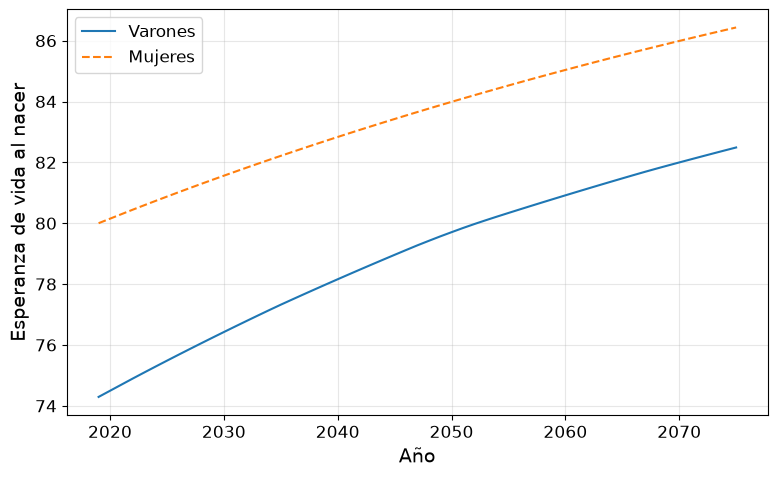

In [7]:
plt.rcParams.update({'font.size': 14})
plt.figure(figsize=(8, 5))
estilos_linea = {"Varones": "-", "Mujeres": "--"}
for sexo in ev_sexo["sexo"].unique():
    datos = ev_sexo[ev_sexo["sexo"] == sexo]
    plt.plot(datos["year"], datos["e0"], linestyle=estilos_linea.get(sexo, "-"), label=sexo)
plt.xlabel("Año", fontsize=14)
plt.ylabel("Esperanza de vida al nacer", fontsize=14)
plt.grid(alpha=0.3)
plt.legend(fontsize=12)
plt.tick_params(axis='both', labelsize=12)
plt.tight_layout()
plt.savefig(DIR_FIG / 'esperanza_vida.png', dpi=300, bbox_inches='tight')
plt.show()